In [500]:
import numpy as np

from astropy.table import Table, QTable
from astropy.time import Time
import astropy.units as u
from astropy.io import fits
from astropy.timeseries import LombScargle

from datetime import datetime, timedelta

from scipy.optimize import curve_fit
from scipy.stats import gaussian_kde

from periapsis.params.units import CanonicalUnits

import glob
import pickle

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.image as img
plt.style.use('figure_style.mplstyle')

def decimal_year_to_datetime(decimal_year):
    # Separate the integer year and the fractional remainder
    year = int(decimal_year)
    remainder = decimal_year - year
    
    # Calculate total seconds in this specific year (handles leap years)
    base_date = datetime(year, 1, 1)
    next_year_date = datetime(year + 1, 1, 1)
    year_seconds = (next_year_date - base_date).total_seconds()
    
    # Add the fractional component back as seconds
    return base_date + timedelta(seconds=remainder * year_seconds)

def vacuum_to_air(vac_wavelength):
    """Convert vacuum wavelengths to air wavelengths using Morton (2000).

    Expects input in Angstroms. Valid for wavelengths > 2000 Å.
    """
    w = np.asarray(vac_wavelength)
    s2 = (10**4 / w) ** 2

    # Calculate index of refraction (n)
    n = (
        1.0
        + 0.0000834254
        + 0.02406147 / (130.0 - s2)
        + 0.00015998 / (38.9 - s2)
    )
    return w / n

def air_to_vacuum(air_wavelength):
    """Convert air wavelengths to vacuum wavelengths using Piskunov's inversion.

    Expects input in Angstroms. Valid for wavelengths > 2000 Å.
    """
    w = np.asarray(air_wavelength)
    s2 = (10**4 / w) ** 2

    # Calculate Piskunov's inversion index multiplier
    n = (
        1.0
        + 0.00008336624212083
        + 0.02408926869968 / (130.1065924522 - s2)
        + 0.0001599740894897 / (38.92568793293 - s2)
    )
    return w * n

color_a = 'orangered'
color_b = 'rebeccapurple'


# RVs over time

## Read in data

In [32]:
exclude2025 = True
mdo_offset = 1.0

dat = Table.read('../HD_79872_radial_velocities_Oct16.csv')
print(dat.colnames)
star_a = (dat['Notes']=='Li-poor star')
star_b = (dat['Notes']=='Li-rich star')
#print(np.nansum(star_a), np.nansum(star_b))

data_a = Table()
data_a['year_day'] = dat['Date'][star_a]
data_a['times_utc'] = dat['Observation Time (UT)'][star_a]
data_a['rv'] = dat['Barycentric RV (km/s)'][star_a]
data_a['e_rv'] = dat['sigma_RV (km/s)'][star_a]
data_a['instr'] = dat['Instrument'][star_a]
n_pts_a = len(data_a['rv'])
date = [Time(data_a['year_day'][i]+'T'+data_a['times_utc'][i], scale='utc').decimalyear for i in range(n_pts_a)]
data_a['date'] = date
if exclude2025:
    data_a = data_a[1::]
n_pts_a = len(data_a['rv'])
tull = (data_a['instr']=='Tull Coudé / HJST')
data_a['rv'][tull] = data_a['rv'][tull] - mdo_offset

data_b = Table()
data_b['year_day'] = dat['Date'][star_b]
data_b['times_utc'] = dat['Observation Time (UT)'][star_b]
data_b['rv'] = dat['Barycentric RV (km/s)'][star_b]
data_b['e_rv'] = dat['sigma_RV (km/s)'][star_b]
data_b['instr'] = dat['Instrument'][star_b]
n_pts_b = len(data_b['rv'])
date = [Time(data_b['year_day'][i]+'T'+data_b['times_utc'][i], scale='utc').decimalyear for i in range(n_pts_b)]
data_b['date'] = date
if exclude2025:
    data_b = data_b[1::]
n_pts_b = len(data_b['rv'])
tull = (data_b['instr']=='Tull Coudé / HJST')
data_b['rv'][tull] = data_b['rv'][tull] - mdo_offset


['Date', 'Star in log', 'Observation Time (UT)', 'Barycentric RV (km/s)', 'sigma_RV (km/s)', 'Notes', 'Instrument']


## Plot

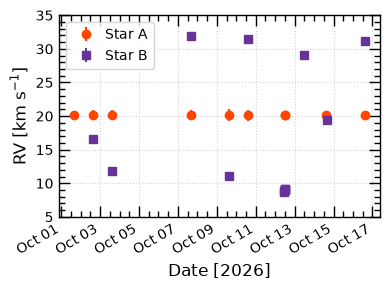

In [56]:
fig = plt.figure(figsize=(4,3))

color_a = 'orangered'
color_b = 'rebeccapurple'

ax = plt.subplot(111)
date_formatter = mdates.DateFormatter('%b %d')
ax.xaxis.set_major_formatter(date_formatter)

dt_a = [decimal_year_to_datetime(data_a['date'][i]) for i in range(n_pts_a)]
plt.errorbar(dt_a, data_a['rv'], yerr=data_a['e_rv'], marker='o', ls='', label='Star A',
             markerfacecolor=color_a, markeredgecolor=color_a, ecolor=color_a, capsize=0.0)

dt_b = [decimal_year_to_datetime(data_b['date'][i]) for i in range(n_pts_b)]
plt.errorbar(dt_b, data_b['rv'], yerr=data_b['e_rv'], marker='s', ls='', label='Star B',
             markerfacecolor=color_b, markeredgecolor=color_b, ecolor=color_b, capsize=0.0)

plt.legend(frameon=True)
plt.ylim([5,35])
plt.xlabel('Date [2026]')
plt.ylabel(r'RV [km s$^{-1}$]')

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig('rv_vs_time.pdf')
fig.savefig('rv_vs_time.png')

In [21]:
print(decimal_year_to_datetime(data_b['date'][0]))

2026-10-02 15:40:57.999998


# SEDs

## Read in data

In [409]:
#Read in data and convert all to same units (A, erg/s/cm^2)

wb74_distance = 74.5*u.pc
radius_b = 1.3*u.solRad
radius_c = 0.29*u.solRad
radius_wd = 1*u.earthRad

sed_path = '/Users/gailzasowski/Dropbox/Documents/science/wide_binaries/wb74/seds/'
phot_a = QTable.read(sed_path+'photometry_wb74a.txt', format='ascii', 
                     names=('filter','mag','flux'))
phot_b = QTable.read(sed_path+'photometry_wb74b.txt', format='ascii', 
                     names=('filter','mag','flux','wave','mag_err'))
wave = phot_b['wave']*u.angstrom
phot_a['flux'] = (phot_a['flux']*u.watt/u.meter**2).to(u.erg/u.s/u.cm**2)
phot_b['flux'] = (phot_b['flux']*u.watt/u.meter**2).to(u.erg/u.s/u.cm**2)
phot_b['flux_err'] = 0.92*phot_b['mag_err']*phot_b['flux']
galex = np.logical_or.reduce([phot_a['filter']=='FUV(ap)',
                              phot_a['filter']=='NUV(ap)'])
phot_a['flux'][galex] = 0.5*phot_a['flux'][galex]
phot_b['flux'][galex] = 0.5*phot_b['flux'][galex]

xp = QTable.read(sed_path+'687376019276147584_xp_model.csv')
xp['xp_flux'] = (xp['xp_flux']*u.watt/(u.meter**2)*xp['wave']).to(u.erg/u.s/u.cm**2)
xp['model_flux'] = (xp['model_flux']*u.watt/(u.meter**2)*xp['wave']).to(u.erg/u.s/u.cm**2)
xp['wave'] = xp['wave']*10*u.angstrom

bosz = QTable.read(sed_path+'bosz2024_mp_t6500_g+4.5_m+0.25_a+0.00_c+0.00_v2_r5000_resam.csv')
bosz['wave'] = bosz['wave']*10*u.angstrom
bosz['flux'] = 4*np.pi*bosz['flux']*bosz['wave']*u.erg/(u.s*u.cm**2) * (radius_b.to(u.cm)/wb74_distance.to(u.cm))**2

bs = QTable.read(sed_path+'phoenixp03_3200.fits')
bs['wave'] = bs['WAVELENGTH'].value*u.angstrom
bs['flux'] = bs['g50'].value*bs['wave']*u.erg/(u.s*u.cm**2) * (radius_c.to(u.cm)/wb74_distance.to(u.cm))**2

wd = QTable.read(sed_path+'WD_10000_8.4_sed.txt', format='ascii')
wd['wave'] = wd['waveobs'].value*u.angstrom
wd['flux'] = 4*np.pi*wd['flux'].value*u.erg/(u.s*u.cm**2) * (radius_wd.to(u.cm)/wb74_distance.to(u.cm))**2

#print(phot_a.colnames)
#print(xp.colnames)
#print(bosz.colnames)
#print(bs.colnames)


## Plot

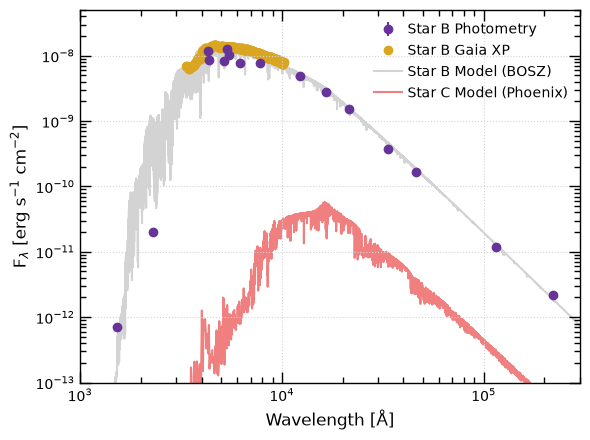

In [420]:
fig = plt.figure(figsize=(6,4.5))

#plt.plot(wave, phot_a['flux'], 'o')
#plt.plot(wave, phot_b['flux'], 'o', label='Photometry', color='rebeccapurple')
plt.errorbar(wave, phot_b['flux'], phot_b['flux_err'], marker='o', color=color_b,
             ecolor='rebeccapurple', capsize=0, ls='', label='Star B Photometry', zorder=4)
plt.plot(xp['wave'], xp['xp_flux'], 'o', zorder=1, label='Star B Gaia XP', color='goldenrod')
plt.plot(bosz['wave'], bosz['flux'], zorder=0, color='lightgray', label='Star B Model (BOSZ)')
plt.plot(bs['wave'], bs['flux'], zorder=0, color='lightcoral', label='Star C Model (Phoenix)')
#plt.plot(bosz['wave'], np.add(bosz['flux'], np.interp(bosz['wave'], bs['wave'], bs['flux'])), 
#         color='yellow', label='Star B + Star C')
#plt.plot(wd['wave'], wd['flux'], zorder=0, color='coral', label='WD Model (BT-SETTL)')

handles, labels = plt.gca().get_legend_handles_labels()
order = [3,0,1,2]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order])
#plt.legend()

plt.xlim([1e3,3e5])
plt.ylim([1e-13,5e-8])
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Wavelength [$\rm \AA$]')
plt.ylabel(r'F$_\lambda$ [erg s$^{-1}$ cm$^{-2}$]')

fig.tight_layout()
fig.savefig('seds.pdf')
fig.savefig('seds.png')

# Lightcurve

## Read in data & get power spectrum

In [276]:
def my_gaussian(x, amplitude, mean, std_dev, const):
    """Returns a baseline-zero Gaussian curve value at x."""
    return amplitude * np.exp(-((x - mean) ** 2) / (2 * std_dev**2)) + const

#lc = Table.read('../TESS_wb74_lc_gail.fits')
lc = Table.read('../tess/TIC86038287_sector21_SPOC_all_columns_with_matched_elk_with_second_pixel_only.csv')
lc['time'] = lc['elk_one_pixel_full_time_btjd']
lc['flux'] = lc['elk_one_pixel_full_flux_electrons_per_second']
lc['flux_err'] = lc['elk_one_pixel_full_flux_error_electrons_per_second']
bd = (lc['flux'].mask == True)
lc['time'][bd] = np.nan
lc['flux'][bd] = np.nan
lc['flux_err'][bd] = np.nan
#print(lc.colnames)
print(len(lc['time']))
#Clean a bit
bd = np.logical_or.reduce([np.isinf(lc['flux'])==True,
                           np.isnan(lc['flux'])==True])
lc = lc[~bd]

ls = LombScargle(lc['time'].value*u.d, 
                 lc['flux'].value*u.flx,
                 lc['flux_err'].value*u.flx, 
                 nterms=1)
freq, power = ls.autopower(minimum_frequency=0.1*1/u.d,
                           maximum_frequency=10*1/u.d,
                           samples_per_peak=50)
period = 1./freq
norm_power = power/np.max(power)
max_period = period.value[np.argmax(norm_power)]

rng = np.logical_and.reduce([period.value >= max_period-0.35, period.value <= max_period+0.35])
popt, pcov = curve_fit(my_gaussian, period[rng], norm_power[rng], p0=[1, max_period, 0.1, 0.05])
print(popt, np.sqrt(np.diag(pcov)))

#TESS pixels
im = img.imread('../tess/image.png')
print(np.shape(im))

19694
[ 1.39164996  4.09384461  0.27977749 -0.40014987] [0.12545266 0.00146841 0.01795851 0.12861289]
(573, 683, 4)


## Plot

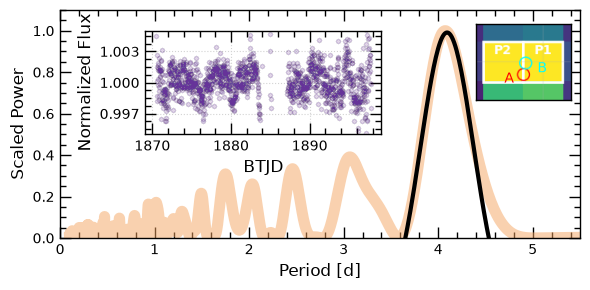

In [298]:
fig = plt.figure(figsize=(6,3))

ax = plt.subplot(111)
plt.plot(period, norm_power, '-', color='sandybrown', lw=8, alpha=0.5)
plt.plot(period, my_gaussian(period.value,popt[0],popt[1],popt[2],popt[3]), 
         color='k', lw=3)
plt.xlim([0,5.5])
plt.ylim([0,1.1])
plt.xlabel('Period [d]')
plt.ylabel('Scaled Power')

ax_in = ax.inset_axes([0.9,0.5,2.5,0.5],
                      transform=ax.transData)
ax_in.plot(lc['time'], lc['flux']/np.nanmedian(lc['flux']), '.', alpha=0.01, color='rebeccapurple')
ax_in.set_ylim([0.995,1.005])
ax_in.set_yticks([0.997, 1.000, 1.003])
ax_in.set_xlabel('BTJD')
ax_in.set_ylabel('Normalized Flux')

ax_in = ax.inset_axes([4.4,0.5,1,0.7],
                      transform=ax.transData)
ax_in.imshow(im[190:275,270:375,:])
plt.text(5.05,0.8,'B',fontsize=10, color='cyan', zorder=10)
plt.text(4.7,0.75,'A',fontsize=10, color='red', zorder=10)
plt.grid(False)
ax_in.set_xticks([])
ax_in.set_yticks([])


fig.tight_layout()
fig.savefig('lightcurve.pdf')
fig.savefig('lightcurve.png')

# Spectra

## Read in spectra

### Old

In [349]:
files = glob.glob('../spectra/Science0*reduced.fits')
file_a = files[3]
file_b = files[2]
print(file_a, file_b)

rv_a = 21.14
rv_b = 10.015

hdu_a = fits.open(file_a)
wave_a, spec_a, err_a = hdu_a[8].data
#wave_a = air_to_vacuum(wave_a)
wave_a = wave_a*(1 - rv_a/3e5)
hdu_a.close()
hdu_b = fits.open(file_b)
wave_b, spec_b, err_b = hdu_b[8].data
wave_b = wave_b*(1 - rv_b/3e5)
#wave_b = vacuum_to_air(wave_b)
hdu_b.close()


../spectra/Science0150_reduced.fits ../spectra/Science0151_reduced.fits


In [380]:
dat = Table.read('../spectra/WB74a_final_5Nov2026.txt', format='ascii')
wave_a, spec_a, err_a = dat['waveobs'], dat['flux'], dat['err']
dat = Table.read('../spectra/WB74b_final_5Nov2026.txt', format='ascii')
wave_b, spec_b, err_b = dat['waveobs'], dat['flux'], dat['err']


## Plot

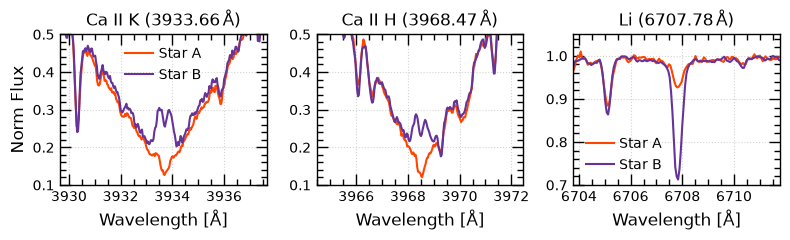

In [382]:
xr_half = 4.0
h_mid = 3968.47
h_rng = [h_mid-xr_half,h_mid+xr_half]
k_mid = 3933.66
k_rng = [k_mid-xr_half,k_mid+xr_half]
li_mid = 6707.78
li_rng = [li_mid-xr_half,li_mid+xr_half]

flux_rng_hk = [0.1,0.5]
flux_rng_li = [0.7,1.05]

fig = plt.figure(figsize=(8,2.5))

#Ca K
ax = plt.subplot(131)
plt.plot(wave_a, spec_a, '-', color=color_a, label='Star A')
plt.plot(wave_b, spec_b, '-', color=color_b, label='Star B')
plt.legend()
plt.xlim(k_rng)
plt.ylim(flux_rng_hk)
plt.xlabel(r'Wavelength [$\rm \AA$]')
plt.ylabel('Norm Flux')
plt.title(r'Ca II K ($3933.66\,\mathrm{\AA}$)')

#Ca H
ax = plt.subplot(132)
plt.plot(wave_a, spec_a, '-', color=color_a, label='Star A')
plt.plot(wave_b, spec_b, '-', color=color_b, label='Star B')
#plt.legend()
plt.xlim(h_rng)
plt.ylim(flux_rng_hk)
plt.xlabel(r'Wavelength [$\rm \AA$]')
plt.title(r'Ca II H ($3968.47\,\mathrm{\AA}$)')

#Li
ax = plt.subplot(133)
plt.plot(wave_a, spec_a, '-', color=color_a, label='Star A')
plt.plot(wave_b, spec_b, '-', color=color_b, label='Star B')
plt.legend()
plt.xlim(li_rng)
plt.ylim(flux_rng_li)
plt.xlabel(r'Wavelength [$\rm \AA$]')
plt.title(r'Li ($6707.78\,\mathrm{\AA}$)')

fig.tight_layout()
fig.savefig('spectra.png')
fig.savefig('spectra.pdf')

In [312]:
print(color_a)

# Orbital parameters

## Define things and read data

In [514]:
def _canonical_to_plot(data, parameter, values, scale=True):
    unit = data.parameter_unit(parameter)
    dimension = data.parameter_dimension(parameter)
    if scale==True:
        return np.asarray(values) / unit.to(CanonicalUnits[dimension])
    else:
        return np.asarray(values)
def _plot_velocity(data, values, scale=True):
    return _canonical_to_plot(data, 'rv', values, scale=scale)
def plot_system(system, system_datas, map_model):
    map_period = map_model['P']
    map_tp = map_model['Tp']
    tfold = np.linspace(map_tp - 0.5 * map_period, map_tp + 0.5 * map_period, 10000)
    phase_fold = (tfold - map_tp + 0.5 * map_period) / map_period
    sort_map = np.argsort(phase_fold)
    ax.plot(
        phase_fold[sort_map],
        _plot_velocity(system_datas[0], map_model.rv(tfold, system), scale=False)[sort_map],
        label='Orbit Fit',
        color='darkgray',
        lw=2,
        linestyle='-'
    )
    for d in system_datas:
        #t_canonical = d.unit_system.convert_to_canonical('t', d.t)
        #rv_canonical = d.unit_system.convert_to_canonical('rv', d.rv)
        #rv_err_canonical = d.unit_system.convert_to_canonical('rv_err', d.rv_err)
        t_canonical = d.t
        rv_canonical = d.rv
        rv_err_canonical = d.rv_err
        phase = (t_canonical - map_tp + 0.5 * map_period) / map_period % 1
        ax.plot(phase, _plot_velocity(d, rv_canonical, scale=True),
                'o', color=color_b, ls='', label='Star B RVs')
        ax.errorbar(phase, _plot_velocity(d, rv_canonical, scale=True), 
                    yerr=_plot_velocity(d, rv_err_canonical, scale=True), 
                    fmt='.', ls='', color=color_b, markersize=0)


with open('../orbit_output.pickle', 'rb') as f:
    # The protocol version used is detected automatically, so we do not
    # have to specify it.
    data = pickle.load(f)
map_model = data['orbit']
rv_data = data['rv_data']
datas = [rv_data]
samples = data['samples']

## Plot

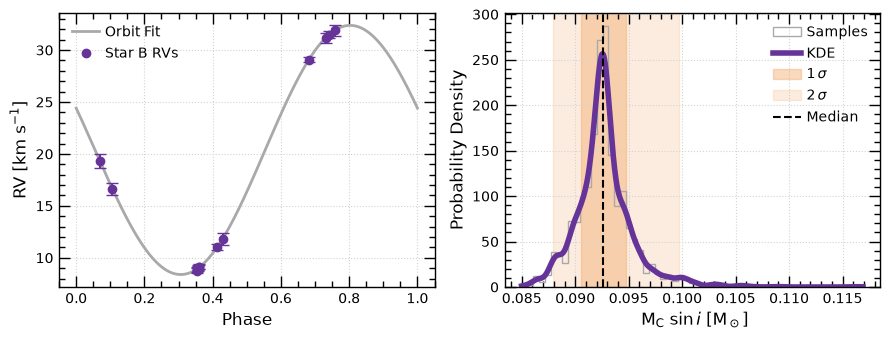

In [535]:
fig = plt.figure(figsize=(9,3.5))
ax = plt.subplot(121)
#for system in sorted({d.system for d in datas}):
#    system_datas = [d for d in datas if d.system == system]
#    plot_system(system, system_datas, map_model)
plot_system(1, datas, map_model)
ax.set_xlabel('Phase')
ax.set_ylabel('RV [km s$^{-1}$]')
ax.legend(loc='best')

ax = plt.subplot(122)
med = np.median(samples)
p16 = np.percentile(samples, 16)
p84 = np.percentile(samples, 84)
par_m2sig = np.percentile(samples, 2.5)
par_p2sig = np.percentile(samples, 97.5)

kde = gaussian_kde(samples)
x = np.linspace(samples.min(), samples.max(), 750)
pdf = kde(x)
#normalize the pdf
pdf /= np.trapezoid(pdf, x)
bins = np.linspace(samples.min(), samples.max(), 60)
ax.hist(samples,bins=bins, density = True, 
        alpha = 1, histtype='step', color='darkgray',label='Samples')
ax.plot(x, pdf, '-', color=color_b, lw=4, label='KDE')
#ax.axvspan(p16,p84,color='sandybrown',alpha=0.35,
#            label=fr'$1\,\sigma$  [{p16:.2f},{p84:.2f}] M$_\odot$')
ax.axvspan(p16,p84,color='sandybrown',alpha=0.4,
            label=fr'$1\,\sigma$')
ax.axvspan(par_m2sig,par_p2sig,color='sandybrown', alpha=0.2,
           label=fr'$2\,\sigma$')
ax.axvline(med,color='k',linestyle='--',
           label=fr'Median')
ax.set_xlabel(r' M$_{\rm C}$ $\sin{i}$ [M$_\odot$]')
ax.set_ylabel("Probability Density")
ax.legend(loc='best')

fig.tight_layout()
fig.savefig('orbit_params.pdf')
fig.savefig('orbit_params.png')
